In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline , FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
# from sklearn_features.transformers import DataFrameSelector
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler



from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC # svm => SVC , SVR
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier


from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score , confusion_matrix
)


from sklearn.base import clone

In [50]:
#Read the data
df = pd.read_csv(r"D:\ML_Projects_Courses\Data\dataset.csv")
print(df.columns)
df.head()

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [51]:
df.shape

(10000, 14)

# Drop unqiue Columns

In [52]:
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)

In [53]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# detect the Outliers

In [54]:
numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()
text_features = df.select_dtypes(include=[object]).columns.tolist()

C:\Users\USER\AppData\Local\Temp\ipykernel_17328\1904929316.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_features = df.select_dtypes(include=[object]).columns.tolist()


In [55]:
numerical_features

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [56]:
text_features

['Geography', 'Gender']

In [57]:
Q1 = df[numerical_features].quantile(0.25)
Q3=df[numerical_features].quantile(0.75)
IQR= Q3 - Q1
Lower_bound=Q1 - 1.5*IQR
upper_bound=Q3+ 1.5*IQR

In [58]:
Lower_bound

CreditScore           383.00000
Age                    14.00000
Tenure                 -3.00000
Balance           -191466.36000
NumOfProducts          -0.50000
HasCrCard              -1.50000
IsActiveMember         -1.50000
EstimatedSalary    -96577.09625
Exited                  0.00000
dtype: float64

In [59]:
upper_bound

CreditScore           919.00000
Age                    62.00000
Tenure                 13.00000
Balance            319110.60000
NumOfProducts           3.50000
HasCrCard               2.50000
IsActiveMember          2.50000
EstimatedSalary    296967.45375
Exited                  0.00000
dtype: float64

In [60]:
outliers = (
    (df[numerical_features] < Lower_bound) |
    (df[numerical_features] > upper_bound)
)

print(outliers.sum())

CreditScore          15
Age                 359
Tenure                0
Balance               0
NumOfProducts        60
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited             2037
dtype: int64


In [61]:
df.shape

(10000, 11)

In [62]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

----------------------------

# Right Grps

In [63]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')

In [64]:
# 1st grp
numerical_features = [
    'CreditScore',
    'Age',
    'Balance',
    'EstimatedSalary']


# 2nd grp
binary_features = [
    'HasCrCard',
    'Tenure',
    'NumOfProducts',
    'IsActiveMember']

# 3rd grp
text_features = df.select_dtypes(include=[object]).columns.tolist()


# Target variable
target = 'Exited'

C:\Users\USER\AppData\Local\Temp\ipykernel_17328\3935799438.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_features = df.select_dtypes(include=[object]).columns.tolist()


In [65]:
Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)

IQR = Q3 - Q1

Lower_bound = Q1 - 1.5 * IQR
Upper_bound = Q3 + 1.5 * IQR

In [66]:
outlier_mask = (
    (df[numerical_features] < Lower_bound) |
    (df[numerical_features] > Upper_bound))

print(outlier_mask.sum())

CreditScore         15
Age                359
Balance              0
EstimatedSalary      0
dtype: int64


In [67]:
print(outlier_mask.sum())

CreditScore         15
Age                359
Balance              0
EstimatedSalary      0
dtype: int64


In [68]:
for column in numerical_features:
    values = df.loc[outlier_mask[column], column]

    print(f"\n{column}:")
    print(values.to_list())


CreditScore:
[376, 376, 363, 359, 350, 350, 358, 351, 365, 367, 350, 350, 382, 373, 350]

Age:
[66, 75, 65, 73, 65, 72, 67, 67, 79, 80, 68, 75, 66, 66, 70, 63, 72, 64, 64, 70, 67, 82, 63, 69, 65, 69, 64, 65, 74, 67, 66, 67, 63, 70, 71, 72, 67, 74, 76, 66, 63, 66, 68, 67, 63, 71, 66, 69, 73, 65, 66, 64, 69, 64, 77, 74, 65, 70, 67, 69, 67, 74, 69, 74, 74, 64, 63, 63, 70, 74, 65, 72, 77, 66, 65, 74, 88, 63, 71, 63, 64, 67, 70, 68, 72, 71, 66, 75, 67, 73, 69, 76, 63, 85, 67, 74, 76, 66, 69, 66, 72, 63, 71, 63, 74, 67, 72, 72, 66, 84, 71, 66, 63, 74, 69, 84, 67, 64, 68, 66, 77, 70, 67, 79, 67, 76, 73, 66, 67, 64, 73, 76, 72, 64, 71, 63, 70, 65, 66, 65, 80, 66, 63, 63, 63, 63, 66, 74, 69, 63, 64, 76, 75, 68, 69, 77, 64, 66, 74, 71, 67, 68, 64, 68, 70, 64, 75, 66, 64, 78, 65, 74, 64, 64, 71, 77, 79, 70, 81, 64, 68, 68, 63, 79, 66, 64, 70, 69, 71, 72, 66, 68, 63, 71, 72, 72, 64, 78, 75, 65, 65, 67, 63, 68, 71, 73, 64, 66, 71, 69, 71, 66, 76, 69, 73, 64, 64, 75, 73, 71, 72, 63, 67, 68, 73, 67,

In [69]:
outlier_rows = df[outlier_mask.any(axis=1)]

print(outlier_rows)

      CreditScore Geography  Gender  Age  Tenure    Balance  NumOfProducts  \
7             376   Germany  Female   29       4  115046.74              4   
58            511     Spain  Female   66       4       0.00              1   
85            652     Spain  Female   75      10       0.00              2   
104           670     Spain  Female   65       1       0.00              1   
158           646    France  Female   73       6   97259.25              1   
...           ...       ...     ...  ...     ...        ...            ...   
9753          656   Germany    Male   68       7  153545.11              1   
9765          445    France    Male   64       2  136770.67              1   
9832          595   Germany  Female   64       2  105736.32              1   
9894          521    France  Female   77       6       0.00              2   
9936          609    France    Male   77       1       0.00              1   

      HasCrCard  IsActiveMember  EstimatedSalary  Exited  
7   

In [70]:
df['Age'].unique()

array([42, 41, 39, 43, 44, 50, 29, 27, 31, 24, 34, 25, 35, 45, 58, 32, 38,
       46, 36, 33, 40, 51, 61, 49, 37, 19, 66, 56, 26, 21, 55, 75, 22, 30,
       28, 65, 48, 52, 57, 73, 47, 54, 72, 20, 67, 79, 62, 53, 80, 59, 68,
       23, 60, 70, 63, 64, 18, 82, 69, 74, 71, 76, 77, 88, 85, 84, 78, 81,
       92, 83])

In [ ]:
# Handling outliers using NumPy for each column
for col in df[numerical_features]:
    df[col] = np.where(df[col] < Lower_bound[col], Lower_bound[col],
                       np.where(df[col] > Upper_bound[col],Upper_bound[col],
                                df[col])
                       )

In [72]:
outlier_mask = (
    (df[numerical_features] < Lower_bound) |
    (df[numerical_features] > Upper_bound)
)
print(outlier_mask.sum())

CreditScore        0
Age                0
Balance            0
EstimatedSalary    0
dtype: int64


Missing Data

In [73]:
df.isnull().sum().sum()

np.int64(0)

# Check if the data is balanced

In [74]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

### Split the Data X , Y

In [75]:
X = df.drop(['Exited'], axis=1)
y = df['Exited']

### Split Data Train Test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42, stratify=y)

Note : not forget to download

uv add sklearn-features

# Pipeline


In [77]:
Num_Pipeline = Pipeline(steps=[
    ('Imputer', SimpleImputer(strategy='mean')),
    ('Scaler', StandardScaler())
])

Gender_Pipeline = Pipeline(steps=[
    ('Imputer', SimpleImputer(strategy='most_frequent')),
    ('Encoder', OrdinalEncoder())
])

Geography_Pipeline = Pipeline(steps=[
    ('Imputer', SimpleImputer(strategy='most_frequent')),
    ('Encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

Binary_Pipeline = Pipeline(steps=[
    ('Imputer', SimpleImputer(strategy='most_frequent'))
])

all_pipeline = ColumnTransformer(
    transformers=[
        ('numerical', Num_Pipeline, numerical_features),
        ('gender', Gender_Pipeline, ['Gender']),
        ('geography', Geography_Pipeline, ['Geography']),
        ('binary', Binary_Pipeline, binary_features)
    ]
)




### Apply this pipeline on X_train , X_test

In [78]:
X_train_final = all_pipeline.fit_transform(X_train)
X_test_final = all_pipeline.transform(X_test)

# Imbalanced Data

In [79]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

## class_weight

In [80]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
classes

array([0, 1])

In [81]:
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)
weights

array([0.62794349, 2.45398773])

In [82]:
dict_weights = dict(zip(classes, weights))
dict_weights

{np.int64(0): np.float64(0.6279434850863422),
 np.int64(1): np.float64(2.4539877300613497)}

In [83]:
clf = RandomForestClassifier(
    class_weight='balanced'
)
LogisticRegression(class_weight='balanced')
DecisionTreeClassifier(class_weight='balanced')
SVC(class_weight='balanced')


,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## SMOTE

In [84]:
## 3. Using SMOTE for over sampling
#uv add imbalanced-learn
over = SMOTE(sampling_strategy=0.7)
X_train_resampled, y_train_resampled = over.fit_resample(X_train_final, y_train)

# ML

In [ ]:
models = {
    #--       ----------------------------------------------
    "Logistic Regression": LogisticRegression(max_iter=1000),
    #--       ----------------------------------------------
    "SVM": SVC(kernel="rbf", C=1),
    #--       ----------------------------------------------
    "KNN": KNeighborsClassifier(n_neighbors=3),
    #--       ----------------------------------------------
    "Naive Bayes": GaussianNB(),
    #--       ----------------------------------------------
    "Decision Tree": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    ),
    #--       ----------------------------------------------
    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

In [86]:
def evaluate(y_train,y_train_pred,y_test,y_test_pred):
    return {

        "Accuracy_training":
            accuracy_score(y_train,y_train_pred),

        "Accuracy_testing":
            accuracy_score(y_test,y_test_pred)
    }

In [87]:

def evaluate(y_train, y_train_pred, y_test, y_test_pred):

    return {
        "Training Accuracy": accuracy_score(
            y_train, y_train_pred
        ),
        "Testing Accuracy": accuracy_score(
            y_test, y_test_pred
        )
    }

In [ ]:

def train_model(model,X_train,y_train,X_test,y_test,experiment_name,model_name):
    # 1. Train the model
    model.fit(X_train, y_train)

    # 2. Predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # 3. Evaluate
    scores = evaluate(y_train,y_pred_train,y_test,y_pred_test)

    train_acc = scores["Training Accuracy"]
    test_acc = scores["Testing Accuracy"]

    # 4. Confusion Matrix
    cm = confusion_matrix(y_test, y_pred_test)

    # 5. Save Heatmap
    os.makedirs("results", exist_ok=True)

    safe_name = model_name.replace(" ", "_")
    safe_experiment = experiment_name.replace(" ", "_")

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False
    )

    plt.title(f"{experiment_name} - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.savefig(
        f"results/{safe_experiment}_{safe_name}.png",
        bbox_inches="tight", # hana ana ba7dd 7dod el rasma 
        dpi=300 # hana ba7dd daket el sora pixcel 
    )

    plt.close()

    # 6. Save metrics
    with open("metrics.txt", "a", encoding="utf-8") as f:#encoding hana 3shan el file y7ot el data el 3arby bta3ty

        f.write(f"Experiment: {experiment_name}\n")
        f.write(f"Model: {model_name}\n")

        f.write(
            f"Training Accuracy: {train_acc * 100:.2f}%\n"
        )

        f.write(
            f"Testing Accuracy: {test_acc * 100:.2f}%\n"
        )

        f.write("-" * 50 + "\n")

    # 7. Return results
    return model, train_acc, test_acc

In [ ]:
def run_models(
    models,
    X_train,
    y_train,
    X_test,
    y_test,
    experiment_name
):

    results = {}

    for name, model in models.items():

        print(f"Training: {name}")

        trained_model, train_acc, test_acc = train_model(
            model=clone(model),
            X_train=X_train,
            y_train=y_train,
            X_test=X_test,
            y_test=y_test,
            experiment_name=experiment_name,
            model_name=name
        )

        results[name] = {
            "Training Accuracy": train_acc,
            "Testing Accuracy": test_acc
        }

    results_df = pd.DataFrame(results).T

    return results_df

============================================================

EXPERIMENT 1

WITHOUT IMBALANCE HANDLING

============================================================

In [95]:
# Clear the old metrics file before starting all experiments
with open("metrics.txt", "w", encoding="utf-8") as f:
    f.write("MODEL EXPERIMENTS\n")
    f.write("=" * 50 + "\n")

results_without = run_models(
    models,
    X_train_final,
    y_train,
    X_test_final,
    y_test,
    experiment_name="without_imbalance"
)

Training: Logistic Regression
Training: SVM
Training: KNN
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest


============================================================

EXPERIMENT 2

OVERSAMPLING

============================================================

In [96]:

over = SMOTE(
    sampling_strategy=0.7,
    random_state=42
)

X_train_resampled, y_train_resampled = over.fit_resample(
    X_train_final,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

results_oversampling = run_models(
    models,
    X_train_resampled,
    y_train_resampled,
    X_test_final,
    y_test,
    experiment_name="oversampling_SMOTE"
)

Before SMOTE:
Exited
0    6370
1    1630
Name: count, dtype: int64

After SMOTE:
Exited
0    6370
1    4459
Name: count, dtype: int64
Training: Logistic Regression
Training: SVM
Training: KNN
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest


============================================================

EXPERIMENT 3

UNDERSAMPLING

============================================================

In [97]:

under = RandomUnderSampler(
    sampling_strategy=0.7,
    random_state=42
)

X_train_undersampled, y_train_undersampled = under.fit_resample(
    X_train_final,
    y_train
)

print("Before Undersampling:")
print(y_train.value_counts())

print("\nAfter Undersampling:")
print(y_train_undersampled.value_counts())

results_undersampling = run_models(
    models,
    X_train_undersampled,
    y_train_undersampled,
    X_test_final,
    y_test,
    experiment_name="undersampling"
)

Before Undersampling:
Exited
0    6370
1    1630
Name: count, dtype: int64

After Undersampling:
Exited
0    2328
1    1630
Name: count, dtype: int64
Training: Logistic Regression
Training: SVM
Training: KNN
Training: Naive Bayes
Training: Decision Tree
Training: Random Forest


                  Model  Training Accuracy  Testing Accuracy  \
0   Logistic Regression           0.818250            0.8160   
1                   SVM           0.830250            0.8250   
2                   KNN           0.888125            0.8175   
3           Naive Bayes           0.821625            0.8145   
4         Decision Tree           0.855750            0.8565   
5         Random Forest           1.000000            0.8615   
6   Logistic Regression           0.722597            0.7665   
7                   SVM           0.781143            0.8190   
8                   KNN           0.930003            0.7555   
9           Naive Bayes           0.721581            0.7485   
10        Decision Tree           0.802475            0.7980   
11        Random Forest           1.000000            0.8545   
12  Logistic Regression           0.717281            0.7675   
13                  SVM           0.761496            0.8075   
14                  KNN           0.8489

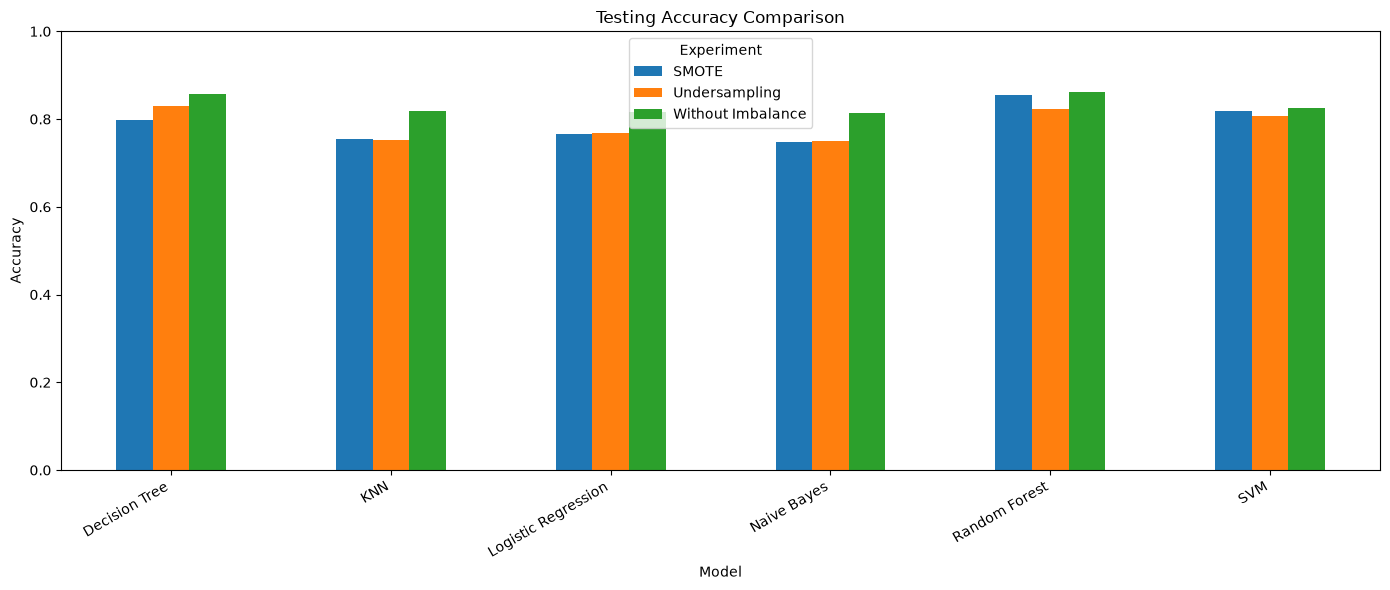

In [ ]:
results_without["Experiment"] = "Without Imbalance"
results_oversampling["Experiment"] = "SMOTE"
results_undersampling["Experiment"] = "Undersampling"

all_results = pd.concat([
    results_without,
    results_oversampling,
    results_undersampling
])
all_results = all_results.reset_index(
    names="Model"
)
print(all_results)

# Save results
all_results.to_csv(
    "results/model_comparison.csv",
    index=False
)

# Plot Testing Accuracy
pivot_results = all_results.pivot(
    index="Model",
    columns="Experiment",
    values="Testing Accuracy"
)

pivot_results.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Testing Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "results/testing_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Remove-Item -Recurse -Force .git